# XGBoost baseline – hydropower unit commitment

**Task.** For each scheduling case (one week = 168 hours, one case per day) predict the probability that each of the
14 generating units in the Tokke–Vinje system is ON at each hour. Evaluation: micro-averaged ROC AUC over all
14 × 168 = 2352 outputs per case.

**Approach in this notebook.**
1. Reshape the wide ground truth (`Run No` × 2352 columns) into one row per *(case, hour)* with 14 binary labels.
2. Build features for each (case, hour): calendar info, the day-ahead price at that hour and relative to the week,
   hourly inflow, and the reservoir volumes / water values at the start of the case.
3. Train one multi-label `XGBClassifier` (XGBoost fits one booster per unit, sharing the same features).
4. Validate with a *time-based* split (train 2015–2021, validate on 2022) using the official Kaggle metric.
5. Refit on all training cases and write a submission file.


In [1]:
# run from the repo root so that data/, results/ and src/ resolve (notebooks live in notebooks/)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))

import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score

from kaggle_metric import score  # official metric, same folder as this notebook

DATA = "data/kernel"
H = 168  # hours per scheduling case
SEED = 42

def pick_device():
    """Use the GPU when this XGBoost build can see one, otherwise fall back to CPU."""
    try:
        xgb.XGBClassifier(n_estimators=1, device="cuda").fit(np.zeros((4, 1)), [0, 1, 0, 1])
        return "cuda"
    except Exception:
        return "cpu"

DEVICE = pick_device()
print("training device:", DEVICE)

# minimal plot style: thin marks, recessive axes, one hue for single-series charts
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})
BLUE = "#2a78d6"

training device: cuda


## 1. Load data

In [2]:
uc = pd.read_csv(f"{DATA}/Unit_commitment_decisions.csv", parse_dates=["starttime"])
test_map = pd.read_csv("prediction_mapping.csv", parse_dates=["starttime"])
sample = pd.read_csv("sample_submission.csv", nrows=1)

# hourly series. The price file switches to 15-min resolution late 2025, so resample everything to hourly means.
price = (pd.read_csv(f"{DATA}/Historical_day_ahead_price_2015_2025.csv", parse_dates=["date"])
           .set_index("date")["Day-ahead price (EUR/MWh)"].resample("h").mean())
inflow = pd.read_csv(f"{DATA}/Historical_inflow_1958_2025.csv", parse_dates=["date"]).set_index("date")
inflow = inflow[inflow.index >= "2014-12-01"].resample("h").mean()   # we only need 2015 onwards

# daily series (value at the start of the day)
volume = pd.read_csv(f"{DATA}/Historical_volume_2015_2024.csv", parse_dates=["date"]).set_index("date")
water_value = pd.read_csv(f"{DATA}/Synthetic_water_value_2015_2024.csv", parse_dates=["date"]).set_index("date")

print(f"train cases: {len(uc)}  ({uc.starttime.min().date()} → {uc.starttime.max().date()})")
print(f"test cases:  {len(test_map)}  ({test_map.starttime.min().date()} → {test_map.starttime.max().date()})")
print("price:", price.index.min(), "→", price.index.max(), "| NaNs:", int(price.isna().sum()))
print("inflow:", inflow.shape, "| volume:", volume.shape, "| water value:", water_value.shape)

train cases: 2922  (2015-01-01 → 2022-12-31)
test cases:  725  (2023-01-01 → 2024-12-25)
price: 2015-01-01 00:00:00+00:00 → 2025-12-31 23:00:00+00:00 | NaNs: 0
inflow: (95312, 18) | volume: (3654, 17) | water value: (3654, 17)


In [3]:
# label columns are named result_committed_<unit>_t<hour>; keep the exact order used by the submission file
label_cols = [c for c in sample.columns if c != "Run No"]
assert label_cols == [c for c in uc.columns if c.startswith("result_committed_")]

units = list(dict.fromkeys(re.match(r"result_committed_(.+)_t\d+$", c).group(1) for c in label_cols))
N_UNITS = len(units)
assert len(label_cols) == N_UNITS * H
units

['Hogga_G1',
 'Tokke_G1',
 'Tokke_G2',
 'Tokke_G3',
 'Tokke_G4',
 'Lio_G1',
 'Byrte_G1',
 'Vinje_G1',
 'Vinje_G2',
 'Vinje_G3',
 'Haukeli_G1',
 'Songa_G1',
 'Kjela_G1',
 'Vesle Kjela_G1']

## 2. Quick look at the targets

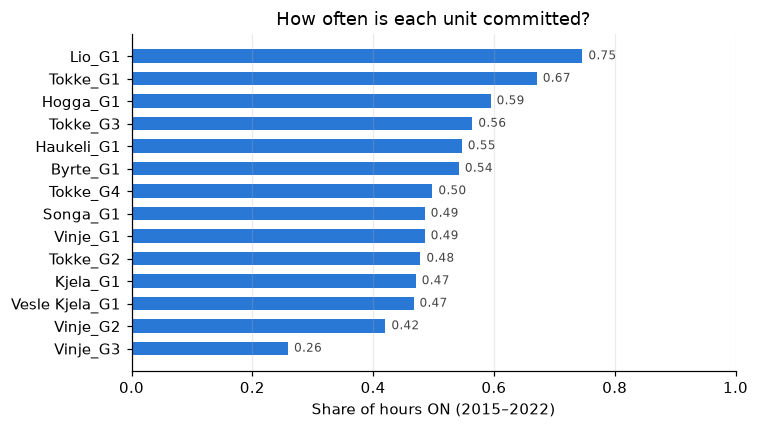

In [4]:
Y_wide = uc[label_cols].to_numpy(dtype=np.int8).reshape(len(uc), N_UNITS, H)  # (case, unit, hour)

on_frac = pd.Series(Y_wide.mean(axis=(0, 2)), index=units).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(on_frac.index, on_frac.values, color=BLUE, height=0.6)
for y, v in enumerate(on_frac.values):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8, color="#444")
ax.set_xlim(0, 1); ax.set_xlabel("Share of hours ON (2015–2022)"); ax.set_title("How often is each unit committed?")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

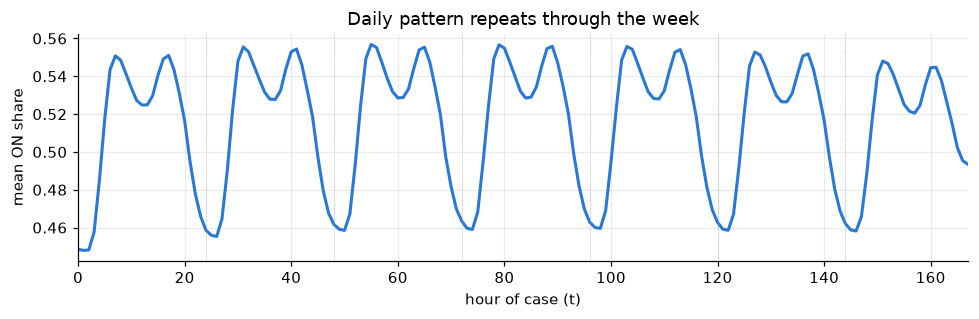

In [5]:
# average commitment over the hour of the week, all units pooled
hourly_on = Y_wide.mean(axis=(0, 1))
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(H), hourly_on, color=BLUE, lw=2)
for d in range(1, 7):
    ax.axvline(d * 24, color="#999", lw=0.5, ls=":")
ax.set_xlabel("hour of case (t)"); ax.set_ylabel("mean ON share"); ax.set_title("Daily pattern repeats through the week")
ax.set_xlim(0, H - 1)
plt.tight_layout(); plt.show()

## 3. Feature engineering

Each case starts at `starttime` (00:00 UTC) and covers hours `t = 0 … 167`. For each (case, hour) row we use:

| group | features |
|---|---|
| calendar | `t`, hour of day, day of week, month, day of year |
| price | price at `t`, week mean/std/min/max, price − week mean, within-week rank, mean of the same day, price at `t−1` and `t+1` |
| inflow | hourly inflow into each of the 17 reservoirs + river, and the total |
| reservoir state | volume and water value of each reservoir at case start, water value at case end (start + 7 days) |

Per-case quantities are simply repeated over the 168 hours of the case.

In [6]:
def window(hourly_df, starts, horizon=H):
    """Hourly values for each case: returns array (n_cases, horizon, n_columns)."""
    idx = hourly_df.index.get_indexer(starts)
    assert (idx >= 0).all(), "some case start times are missing from the hourly series"
    pos = idx[:, None] + np.arange(horizon)[None, :]
    return hourly_df.to_numpy(dtype=np.float32)[pos]


def build_features(starts):
    starts = pd.DatetimeIndex(starts)
    if starts.tz is None:
        starts = starts.tz_localize("UTC")
    n = len(starts)

    P = window(price.to_frame(), starts)[:, :, 0]                       # (n, 168)
    I = window(inflow, starts)                                           # (n, 168, 18)
    V = volume.reindex(starts).to_numpy(dtype=np.float32)                # (n, 17)
    W = water_value.reindex(starts).to_numpy(dtype=np.float32)           # (n, 17)
    W_end = water_value.reindex(starts + pd.Timedelta(days=7)).to_numpy(dtype=np.float32)

    hours = pd.DatetimeIndex((starts.values[:, None] + np.arange(H)[None, :] * np.timedelta64(1, "h")).ravel())
    rep = lambda a: np.repeat(a, H)   # broadcast a per-case value to all 168 hours

    f = pd.DataFrame({
        "t": np.tile(np.arange(H), n),
        "hour": hours.hour, "dow": hours.dayofweek, "month": hours.month, "doy": hours.dayofyear,
        "price": P.ravel(),
        "price_week_mean": rep(P.mean(1)), "price_week_std": rep(P.std(1)),
        "price_week_min": rep(P.min(1)), "price_week_max": rep(P.max(1)),
    })
    f["price_rel"] = f["price"] - f["price_week_mean"]
    f["price_rank"] = (P.argsort(1).argsort(1) / (H - 1)).ravel()
    f["price_day_mean"] = np.repeat(P.reshape(n, 7, 24).mean(2), 24, axis=1).ravel()
    f["price_prev"] = np.roll(P, 1, axis=1).ravel()
    f["price_next"] = np.roll(P, -1, axis=1).ravel()

    for j, c in enumerate(inflow.columns):
        f[f"inflow_{c}"] = I[:, :, j].ravel()
    f["inflow_total"] = I.sum(2).ravel()
    for j, c in enumerate(volume.columns):
        f[f"vol_{c}"] = rep(V[:, j])
    for j, c in enumerate(water_value.columns):
        f[f"wv_{c}"] = rep(W[:, j])
    for j, c in enumerate(water_value.columns):
        f[f"wv_end_{c}"] = rep(W_end[:, j])
    return f


def build_targets(Y_wide):
    """(case, unit, hour) -> one row per (case, hour) with N_UNITS columns."""
    return Y_wide.transpose(0, 2, 1).reshape(-1, N_UNITS)


def to_wide(pred_long, run_ids):
    """Inverse of build_targets: (n_cases*168, N_UNITS) -> submission-shaped DataFrame."""
    wide = pred_long.reshape(len(run_ids), H, N_UNITS).transpose(0, 2, 1).reshape(len(run_ids), -1)
    out = pd.DataFrame(wide, columns=label_cols)
    out.insert(0, "Run No", np.asarray(run_ids))
    return out

In [7]:
t0 = time.time()
X = build_features(uc["starttime"])
Y = build_targets(Y_wide)
case_year = np.repeat(uc["starttime"].dt.year.to_numpy(), H)   # year of each row, for the time split
print(f"X: {X.shape}, Y: {Y.shape}, NaNs in X: {int(X.isna().sum().sum())}, built in {time.time() - t0:.1f}s")
X.head()

X: (490896, 85), Y: (490896, 14), NaNs in X: 0, built in 0.4s


,t,hour,dow,month,doy,price,price_week_mean,price_week_std,price_week_min,price_week_max,...,wv_end_Vaamarvatn,wv_end_Langeidvatn,wv_end_Totak,wv_end_Songavatn,wv_end_Vinjevatn,wv_end_Bandak,wv_end_Bordalsvatn,wv_end_Byrtevatn,wv_end_Hyljelihyl,wv_end_Vatjern
0,0,0,3,1,1,27.070000,28.980474,3.902484,24.74,56.779999,...,25.299999,3.82,25.299999,27.870001,19.65,0.01,27.719999,6.92,25.299999,3.82
1,1,1,3,1,1,26.930000,28.980474,3.902484,24.74,56.779999,...,25.299999,3.82,25.299999,27.870001,19.65,0.01,27.719999,6.92,25.299999,3.82
2,2,2,3,1,1,26.830000,28.980474,3.902484,24.74,56.779999,...,25.299999,3.82,25.299999,27.870001,19.65,0.01,27.719999,6.92,25.299999,3.82
3,3,3,3,1,1,26.809999,28.980474,3.902484,24.74,56.779999,...,25.299999,3.82,25.299999,27.870001,19.65,0.01,27.719999,6.92,25.299999,3.82
4,4,4,3,1,1,26.969999,28.980474,3.902484,24.74,56.779999,...,25.299999,3.82,25.299999,27.870001,19.65,0.01,27.719999,6.92,25.299999,3.82


## 4. Train with a time-based validation split

Cases are consecutive weeks, so a random split would leak almost identical neighbouring weeks between train and
validation. We hold out the whole of 2022 instead.

In [8]:
train_mask = case_year < 2022
val_mask = ~train_mask

params = dict(
    n_estimators=3000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    tree_method="hist", device=DEVICE, random_state=SEED,
    eval_metric="auc", early_stopping_rounds=100,
)

t0 = time.time()
model = xgb.XGBClassifier(**params)
model.fit(X[train_mask], Y[train_mask], eval_set=[(X[val_mask], Y[val_mask])], verbose=100)
print(f"best iteration: {model.best_iteration}, trained in {time.time() - t0:.0f}s")

[0]	validation_0-auc:0.63681


[100]	validation_0-auc:0.80274


[200]	validation_0-auc:0.82746


[300]	validation_0-auc:0.83796


[400]	validation_0-auc:0.84417


...

[1500]	validation_0-auc:0.86366


[1600]	validation_0-auc:0.86478


[1700]	validation_0-auc:0.86492


[1737]	validation_0-auc:0.86475


best iteration: 1637, trained in 192s


In [9]:
val_pred = model.predict_proba(X[val_mask])          # (n_val_rows, 14) probabilities of ON
val_runs = uc.loc[uc.starttime.dt.year == 2022, "Run No"]

kaggle_auc = score(to_wide(Y[val_mask], val_runs), to_wide(val_pred, val_runs))
print(f"2022 hold-out micro ROC AUC (official metric): {kaggle_auc:.4f}")

per_unit = pd.DataFrame({
    "on_share": Y[val_mask].mean(0),
    "roc_auc": [roc_auc_score(Y[val_mask][:, j], val_pred[:, j]) for j in range(N_UNITS)],
}, index=units).sort_values("roc_auc")
per_unit.round(3)

C:\Users\thoma\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\core.py:569: UserWarning: [09:34:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


2022 hold-out micro ROC AUC (official metric): 0.8623


,on_share,roc_auc
Lio_G1,0.550,0.721
Kjela_G1,0.453,0.745
Songa_G1,0.117,0.812
Haukeli_G1,0.141,0.836
Byrte_G1,0.383,0.856
Vesle Kjela_G1,0.306,0.881
Tokke_G4,0.373,0.889
Hogga_G1,0.387,0.895
Tokke_G3,0.411,0.902
Vinje_G1,0.344,0.907


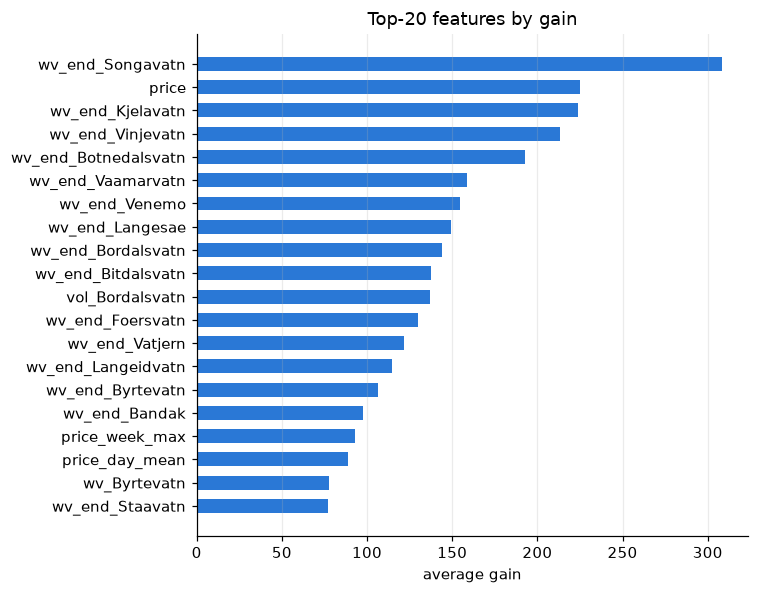

In [10]:
# which features does the model lean on? (gain, summed over the 14 boosters)
imp = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values().tail(20)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_xlabel("average gain"); ax.set_title("Top-20 features by gain"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 5. Refit on all training cases and create the submission

We reuse the number of boosting rounds found by early stopping and train on 2015–2022.

In [11]:
t0 = time.time()
final_params = {**params, "n_estimators": model.best_iteration + 1}
final_params.pop("early_stopping_rounds")
final_model = xgb.XGBClassifier(**final_params).fit(X, Y)
print(f"refit on {len(uc)} cases in {time.time() - t0:.0f}s")

# in-sample AUC of the final model. Optimistic by construction (it has seen these labels);
# the 2022 hold-out score above is the honest estimate of test performance.
train_auc = score(to_wide(Y, uc["Run No"]), to_wide(final_model.predict_proba(X), uc["Run No"]))
print(f"final model, in-sample micro ROC AUC on 2015-2022: {train_auc:.4f}")

X_test = build_features(test_map["starttime"])
test_pred = final_model.predict_proba(X_test)
submission = to_wide(test_pred, test_map["Run No"])

assert list(submission.columns) == list(sample.columns)
assert submission.shape == (len(test_map), 1 + N_UNITS * H)
vals = submission[label_cols].to_numpy()
assert ((vals >= 0) & (vals <= 1)).all()

submission.to_csv("submission_xgb_baseline.csv", index=False)
print("saved submission_xgb_baseline.csv", submission.shape)
submission.iloc[:3, :6]

refit on 2922 cases in 197s


final model, in-sample micro ROC AUC on 2015-2022: 0.9999


saved submission_xgb_baseline.csv (725, 2353)


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4
0,2923,0.023259,0.033927,0.010413,0.003185,0.002196
1,2924,0.979593,0.973059,0.971253,0.976380,0.948457
2,2925,0.999476,0.999132,0.998643,0.997056,0.999457


## Next steps

Ideas to improve on this baseline, roughly in order of expected payoff:

- **Price relative to water value.** A unit runs when the price beats the marginal value of the water feeding it.
  Add `price − wv_<reservoir>` for the reservoir upstream of each plant (see `Tokke_topology.pdf`).
- **Reservoir fill fraction.** Divide volumes by `max_vol` from `Tokke_Vinje_topology.yaml`; the model sees
  absolute volumes now, which have very different scales per reservoir.
- **Constraints.** Minimum flow / minimum volume constraints from `data/extended` force some units on.
- **Lagged labels.** The schedule of the previous case (one day earlier) overlaps 6 of the 7 days. In the test set
  these are not available, but the *last training case* is, and auto-regressive features can be simulated.
- **Tuning.** Lower the learning rate (0.03) with more rounds, try `max_depth` 8, and cross-validate over several
  held-out years instead of only 2022.
- **Per-unit models** with unit-specific feature subsets, or a model that includes unit as a feature so that
  units can share statistical strength.